# A Transformer-Based Approach for Raw EEG Classification

## 1. Setup and Imports

Import necessary libraries and set up the environment.



In [8]:
%load_ext autoreload
%autoreload 2 
#%autoreload 2 fa in modo che, ogni volta che modifichi e salvi un file .py, Jupyter ricarichi automaticamente le modifiche nel notebook senza chiederti di riavviare il kernel!†

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
import numpy as np
from pathlib import Path
import re
import sys

src_path = Path('../src/eeg-bci-transformer-pipeline').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from datapreprocessing import EEGpreprocessing, EEGDataset
from train import  EEGTrainer
from models import F_CTrans , F_CTrans_modified


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import mne
import os
from sklearn.model_selection import KFold,GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Data Loading and Preprocessing

Load the PhysioNet EEG Motor Movement/Imagery Dataset 

In [3]:
CURRENT_DIR = Path.cwd()

DATASET_PATH = (CURRENT_DIR.parent / "data" / "MotorImagery(04,08,012)") 

print(f"Dataset path used: {DATASET_PATH}")

edf_files = sorted(DATASET_PATH.glob("**/*.edf"))

file_records = []
for edf_path in edf_files:
    filename = edf_path.stem
    match = re.search(r'S(\d+)', filename, re.IGNORECASE)
    if match:
        subj_id = int(match.group(1))
        file_records.append({'path': edf_path, 'subject_id': subj_id})

file_subject_ids = np.array([r['subject_id'] for r in file_records])
unique_subjects = np.unique(file_subject_ids)

np.random.seed(42)
shuffled_subjects = unique_subjects.copy()
np.random.shuffle(shuffled_subjects)

test_subjects = set(shuffled_subjects[:11])
train_val_subjects = set(shuffled_subjects[11:])

train_val_records = [r for r in file_records if r['subject_id'] in train_val_subjects]
test_records = [r for r in file_records if r['subject_id'] in test_subjects]

print(f"File EDF for Train/Validation: {len(train_val_records)}")
print(f"File EDF for TEST: {len(test_records)}")


Dataset path used: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)
File EDF for Train/Validation: 294
File EDF for TEST: 33


Apply preprocessing  #momontaneamente lo faccio solo sul train/val perchè non sono sicura vada fatto sul test, riparlarne con luca

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Subject Processing {subj_id} - File: {file_path}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
    except Exception as e:
        print(f"❌ ERROR: Unable to read Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Subject {subj_id}. Jump.")
        continue
    
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Label extraction and mapping (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

   
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_raw_list)}")

Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
N

/tmp/ipykernel_120782/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...


/tmp/ipykernel_120782/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R08.edf
Used Annotations descriptio

/tmp/ipykernel_120782/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


... (3 outputs left out)

/tmp/ipykernel_120782/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
/tmp/ipykernel_120782/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_120782/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 e

Convert to PyTorch tensors

In [5]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Shape X_train_val : {X_training_validation_raw.shape}")
print(f"Shape y_train_val: {y_training_validation.shape}")
print("Label distribution:", np.unique(y_training_validation, return_counts=True))

Shape X_train_val : (4370, 64, 641)
Shape y_train_val: (4370,)
Label distribution: (array([0, 1]), array([2205, 2165]))


##  Cross-Individual 5-Fold Cross-Validation



### f_CTrans with MultiStepLR 

In this section I implement the f_CTrans of the blabla article using the information in section "C. Training Setup"  and in "Table I", I emphasize the use of the MultiStepLR as scheduler

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.80096, train_acc=48.89%, val_loss=0.69630, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69703, train_acc=50.33%, val_loss=0.71625, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69997, train_acc=50.59%, val_loss=0.69448, val_acc=49.94% | LR: 0.001000
Epoch 04/50: train_loss=0.69620, train_acc=49.96%, val_loss=0.69322, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69784, train_acc=50.22%, val_loss=0.69437, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69544, train_acc=50.04%, val_loss=0.69488, val_acc=50.06% | L

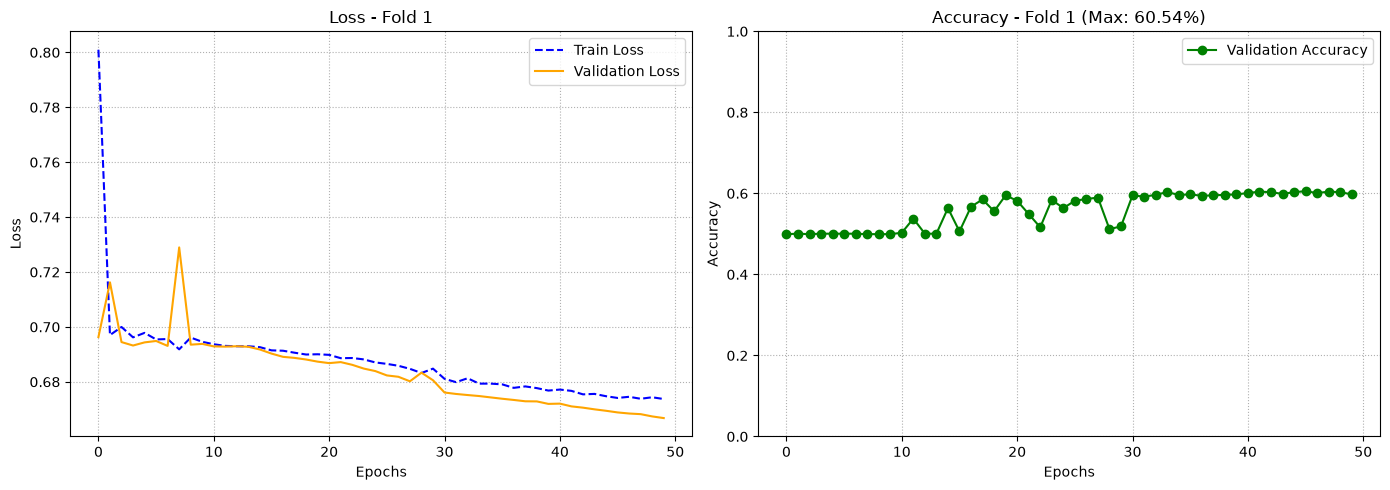


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 60.54% (± 0.00%)


In [21]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

### f_CTrans with ReduceLROnPlateau

In this section, visto lo stagnare della val_acc, ho cambiato lo scheduler per poter adattare il tasso di apprendimento in tempo reale

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.78384, train_acc=49.33%, val_loss=0.69565, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69906, train_acc=49.27%, val_loss=0.69351, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.69704, train_acc=49.10%, val_loss=0.69316, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69776, train_acc=50.65%, val_loss=0.69311, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69653, train_acc=50.04%, val_loss=0.69316, val_acc=49.94% | LR: 0.001000
Epoch 06/50: train_loss=0.69528, train_acc=49.61%, val_loss=0.69638, val_acc=49.94% | L

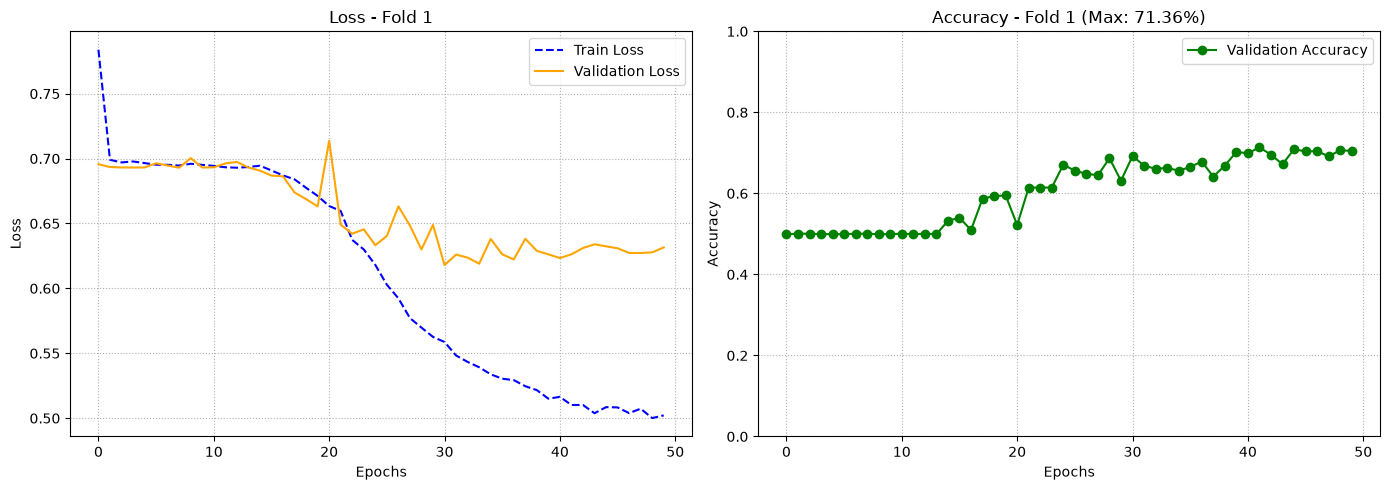


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.36% (± 0.00%)


In [ ]:
'''
#   Qui sbaglaivo perchè nel training avevo messo  ma nello scheduler usavo mode=max controllando la val_acc

#if scheduler is not None:
#    if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
#        scheduler.step(val_loss)  # ReduceLROnPlateau esige la validation loss
#    else:
#        scheduler.step()    


from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")
'''

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.77137, train_acc=50.39%, val_loss=0.70868, val_acc=50.06% | LR: 0.001000
Epoch 02/50: train_loss=0.70612, train_acc=48.87%, val_loss=0.69807, val_acc=50.06% | LR: 0.001000
Epoch 03/50: train_loss=0.70087, train_acc=50.73%, val_loss=0.71991, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69974, train_acc=50.13%, val_loss=0.69320, val_acc=50.06% | LR: 0.001000
Epoch 05/50: train_loss=0.69465, train_acc=50.39%, val_loss=0.70483, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69492, train_acc=50.39%, val_loss=0.70186, val_acc=49.94% | L

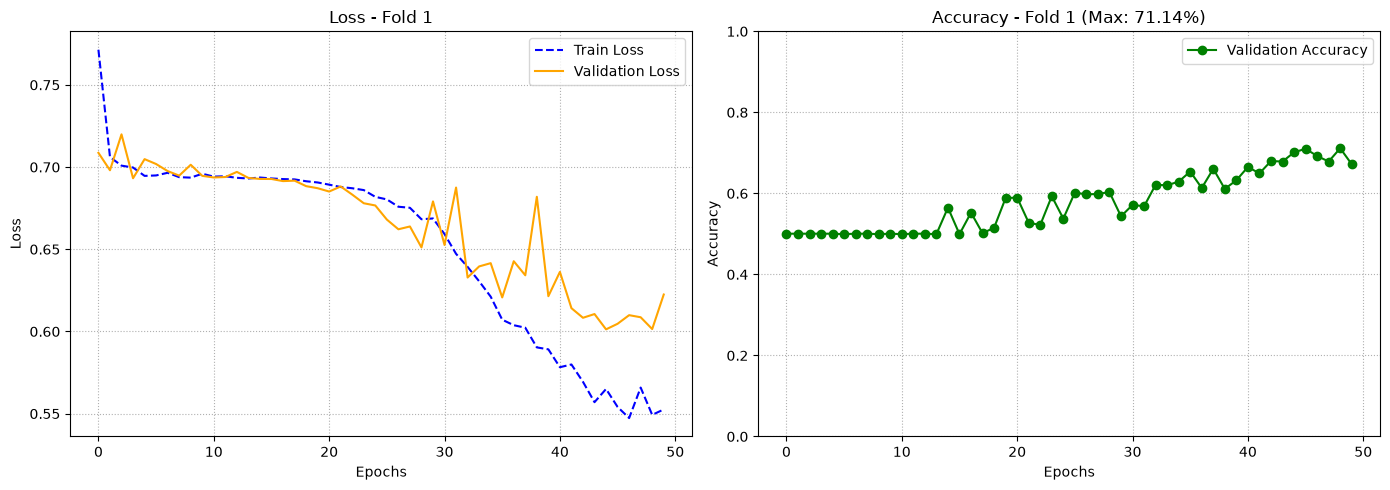


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.14% (± 0.00%)


In [10]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/100: train_loss=0.79946, train_acc=49.44%, val_loss=0.69316, val_acc=49.94% | LR: 0.001000
Epoch 02/100: train_loss=0.70547, train_acc=50.10%, val_loss=0.69362, val_acc=50.06% | LR: 0.001000
Epoch 03/100: train_loss=0.69597, train_acc=50.30%, val_loss=0.69312, val_acc=49.94% | LR: 0.001000
Epoch 04/100: train_loss=0.69910, train_acc=50.99%, val_loss=0.69330, val_acc=50.06% | LR: 0.001000
Epoch 05/100: train_loss=0.69647, train_acc=50.42%, val_loss=0.69324, val_acc=49.94% | LR: 0.001000
Epoch 06/100: train_loss=0.69552, train_acc=49.07%, val_loss=0.69336, val_acc=49.9

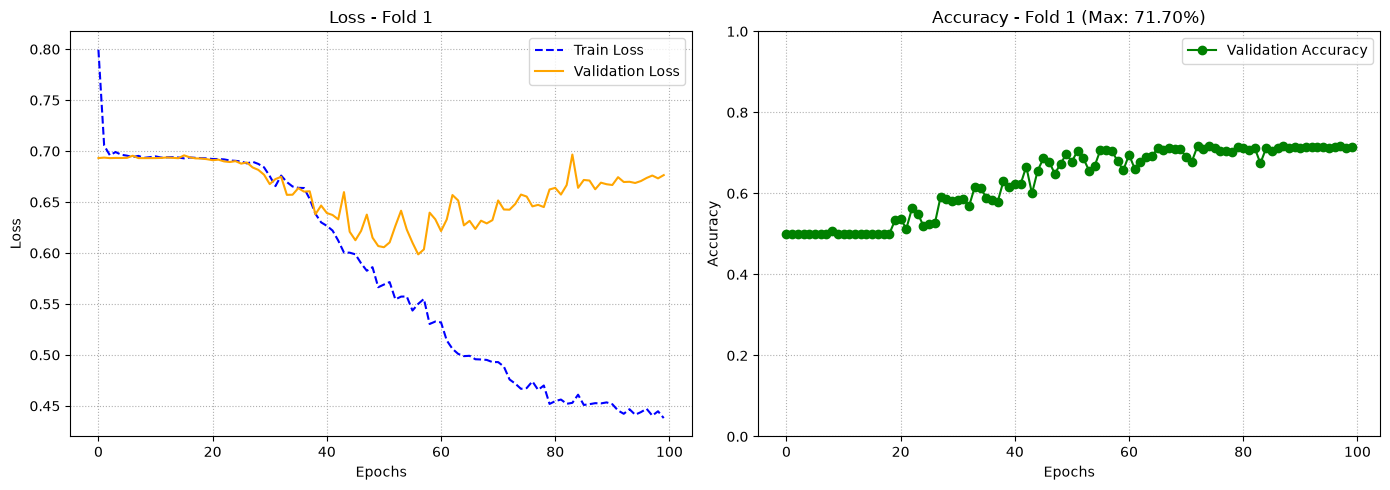


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.70% (± 0.00%)


In [11]:
#aumento epoche

from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 100           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 481]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.71444, train_acc=50.56%, val_loss=0.70240, val_acc=48.93% | LR: 0.001000
Epoch 02/50: train_loss=0.69926, train_acc=48.47%, val_loss=0.69327, val_acc=48.93% | LR: 0.001000
Epoch 03/50: train_loss=0.69557, train_acc=50.99%, val_loss=0.70446, val_acc=48.93% | LR: 0.001000
Epoch 04/50: train_loss=0.69552, train_acc=49.53%, val_loss=0.69359, val_acc=48.93% | LR: 0.001000
Epoch 05/50: train_loss=0.69454, train_acc=49.36%, val_loss=0.69442, val_acc=48.93% | LR: 0.001000
Epoch 06/50: train_loss=0.69383, train_acc=50.84%, val_loss=0.69526, val_acc=48.93% | L

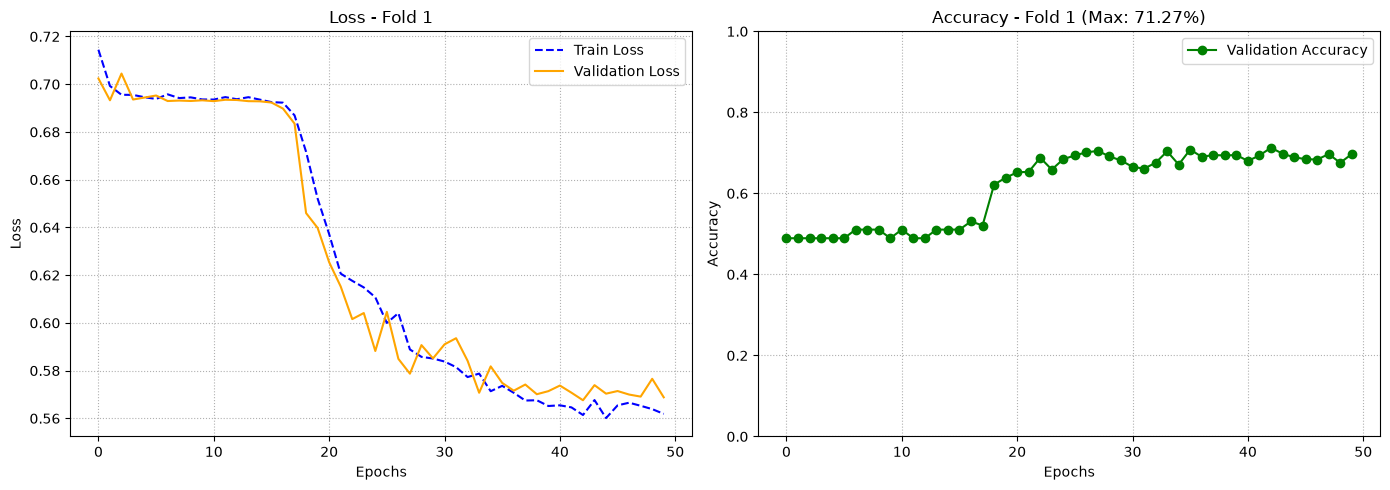


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 71.27% (± 0.00%)


In [7]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modify(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

# PROVO con. dati da 4 sec

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import mne

X_raw_list = []
y_list = []
subject_ids_list = []
psd_records = []  

for i, rec in enumerate(train_val_records):
    file_path = rec['path']
    subj_id = rec['subject_id']

    print(f"Subject Processing {subj_id} - File: {file_path}")

    try:
        raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
    except Exception as e:
        print(f"❌ ERROR: Unable to read Subject file {subj_id}!")
        print(f"   Path: {file_path}")
        print(f"   Detail: {e}")
        continue

    pipeline = EEGpreprocessing(raw)
    pipeline.bandpassfilter(l_freq=8.0, h_freq=30.0, target_sfreq=160.0)
    epochs_mne = pipeline.epoching(tmin=0.0, tmax=4.0)

    if len(epochs_mne) == 0:
        print(f"⚠️ Warning: No epoch found for Subject {subj_id}. Jump.")
        continue
    
    psd_object = epochs_mne.compute_psd(fmin=1, fmax=40, method='welch', verbose=False)
    psd_values, freqs = psd_object.get_data(return_freqs=True) 
    
    psd_records.append({
        'subject_id': subj_id,
        'frequencies': freqs,
        'psd_data': psd_values,
        'mean_power_per_channel': np.mean(psd_values, axis=(0, 2))
    })

    X_raw = epochs_mne.get_data(copy=True) # Shape: (n_trials, 64, 480)

    # Label extraction and mapping (Left = 0, Right = 1)
    y = epochs_mne.events[:, -1]
    event_id = epochs_mne.event_id
    
    labels = np.zeros(len(y), dtype=np.int64)
    if 'Left' in event_id and event_id['Left'] in y:
        labels[y == event_id['Left']] = 0
    if 'Right' in event_id and event_id['Right'] in y:
        labels[y == event_id['Right']] = 1

   
    X_raw_list.append(X_raw)
    y_list.append(labels)
    subject_ids_list.extend([subj_id] * len(X_raw))

print(" Extraction cycle completed successfully!")
print(f"Subjects processed correctly: {len(X_raw_list)}")

Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 1 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S001/S001R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
N

/tmp/ipykernel_119626/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
1 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
10 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 10 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R08.edf


/tmp/ipykernel_119626/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 35 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S035/S035R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 36 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S036/S036R04.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 eve

/tmp/ipykernel_119626/2250886293.py:17: RuntimeWarning: Number of records from the header does not match the file size (perhaps the recording was not stopped before exiting). Inferring from the file size.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


... (3 outputs left out)

/tmp/ipykernel_119626/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError
/tmp/ipykernel_119626/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 100 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S100/S100R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
12 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 12 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R04.edf


/tmp/ipykernel_119626/2250886293.py:17: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(file_path, preload=True, verbose=False, encoding='latin1') #specific encoding='latin1' to avoid UnicodeDecodeError


Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R08.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 events and 641 original time points ...
0 bad epochs dropped
Subject Processing 101 - File: /home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/data/MotorImagery(04,08,012)/S101/S101R12.edf
Used Annotations descriptions: ['T0', 'T1', 'T2']
Not setting metadata
15 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 15 e

In [11]:
X_training_validation_raw = np.concatenate(X_raw_list, axis=0)
y_training_validation = np.concatenate(y_list, axis=0)
subjects_ids_training_validation = np.array(subject_ids_list)

print(f"Shape X_train_val : {X_training_validation_raw.shape}")
print(f"Shape y_train_val: {y_training_validation.shape}")
print("Label distribution:", np.unique(y_training_validation, return_counts=True))

Shape X_train_val : (4370, 64, 641)
Shape y_train_val: (4370,)
Label distribution: (array([0, 1]), array([2205, 2165]))


 Detected device: GPU NVIDIA (CUDA)

--- START TRAINING AND VALIDAZIONE - FOLD 1/5 ---
Quick training batch check...
Input batch shape: torch.Size([64, 64, 641]) (Expected: [Batch, 64, 641])
Labels batch shape: torch.Size([64]) (Expected: [Batch])
Labels data type: torch.int64 (Expected: torch.int64)
Model output shape: torch.Size([64, 2]) (Expected: [Batch, 2])
Diagnostics passed successfully! Starting epochs...

Epoch 01/50: train_loss=0.70397, train_acc=50.01%, val_loss=0.69369, val_acc=49.94% | LR: 0.001000
Epoch 02/50: train_loss=0.69936, train_acc=49.76%, val_loss=0.69617, val_acc=49.94% | LR: 0.001000
Epoch 03/50: train_loss=0.69529, train_acc=51.68%, val_loss=0.69330, val_acc=50.06% | LR: 0.001000
Epoch 04/50: train_loss=0.69428, train_acc=50.96%, val_loss=0.69382, val_acc=49.94% | LR: 0.001000
Epoch 05/50: train_loss=0.69487, train_acc=49.81%, val_loss=0.69670, val_acc=50.06% | LR: 0.001000
Epoch 06/50: train_loss=0.69560, train_acc=48.66%, val_loss=0.69312, val_acc=49.94% | L

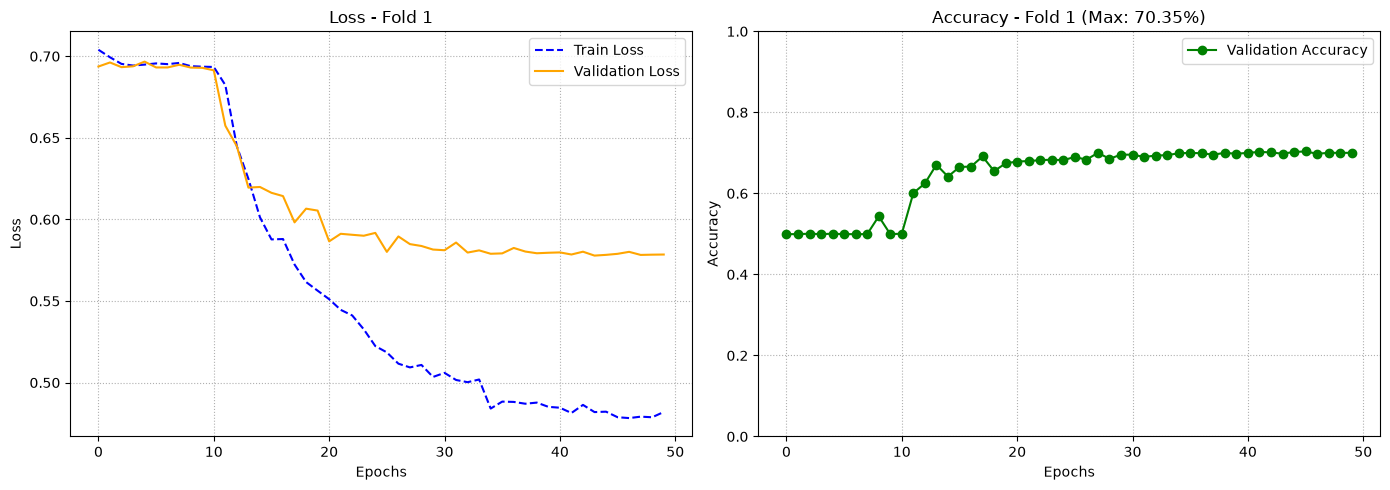


🎉 TRAINING COMPLETED ON ALL FOLD!
📊 Accuracy media cross-validation: 70.35% (± 0.00%)


In [12]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.optim.lr_scheduler import MultiStepLR

import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR


if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("Detected device: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(" Detected device: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("Detected device: CPU")


BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- START TRAINING AND VALIDAZIONE - FOLD {fold + 1}/5 ---")

    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    
    model = F_CTrans_modify(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 2, num_classes =2).to(device)
  
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(optimizer,mode='max',factor=0.5,patience=5,min_lr=1e-6)
  
    trainer = EEGTrainer(model=model,criterion=criterion,optimizer=optimizer,device=device)

    print("Quick training batch check...")
    for inputs, labels in train_loader:
        print(f"Input batch shape: {inputs.shape} (Expected: [Batch, 64, 641])")
        print(f"Labels batch shape: {labels.shape} (Expected: [Batch])")
        print(f"Labels data type: {labels.dtype} (Expected: torch.int64)")
        
        # Forward pass test to check for any shape crashes
        outputs, _ = model(inputs.to(device))
        print(f"Model output shape: {outputs.shape} (Expected: [Batch, 2])")
        break
    print("Diagnostics passed successfully! Starting epochs...\n")

   
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(train_loader=train_loader, val_loader=val_loader,epochs=EPOCHS, scheduler=scheduler)

    fold_accuracies.append(best_val_acc)
    print(f" Fold {fold + 1} completed | Best Val Acc: {best_val_acc*100:.2f}%")

    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETED ON ALL FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")

In [ ]:
SELECTED_CHANNEL_INDICES = [0, 1, 2, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 18, 19 , 20 ]

# GRid search con vecchio scheduler

🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)

--- COMBINAZIONE 1/2 ---
Parametri attuali: {'num_layers': 2}

--- FOLD 1/5 ---


/home/local/ADUNIPI/m.sonetto/mtransformer/eeg-bci-transformer-pipeline/venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


Epoch 01/50: train_loss=0.72141, train_acc=49.01%, val_loss=0.69305, val_acc=51.07% | LR: 0.001000
Epoch 02/50: train_loss=0.69467, train_acc=52.02%, val_loss=0.69377, val_acc=48.93% | LR: 0.001000
Epoch 03/50: train_loss=0.69327, train_acc=50.90%, val_loss=0.69361, val_acc=48.93% | LR: 0.001000
Epoch 04/50: train_loss=0.69747, train_acc=48.47%, val_loss=0.69636, val_acc=51.07% | LR: 0.001000
Epoch 05/50: train_loss=0.69683, train_acc=51.10%, val_loss=0.69292, val_acc=51.07% | LR: 0.001000
Epoch 06/50: train_loss=0.69410, train_acc=49.90%, val_loss=0.69354, val_acc=51.07% | LR: 0.001000
Epoch 07/50: train_loss=0.69448, train_acc=51.02%, val_loss=0.69420, val_acc=48.93% | LR: 0.001000
Epoch 08/50: train_loss=0.69436, train_acc=50.87%, val_loss=0.69435, val_acc=48.93% | LR: 0.001000
Epoch 09/50: train_loss=0.69603, train_acc=49.53%, val_loss=0.69297, val_acc=51.07% | LR: 0.001000
Epoch 10/50: train_loss=0.69399, train_acc=50.59%, val_loss=0.69361, val_acc=48.93% | LR: 0.000100
Epoch 11/5

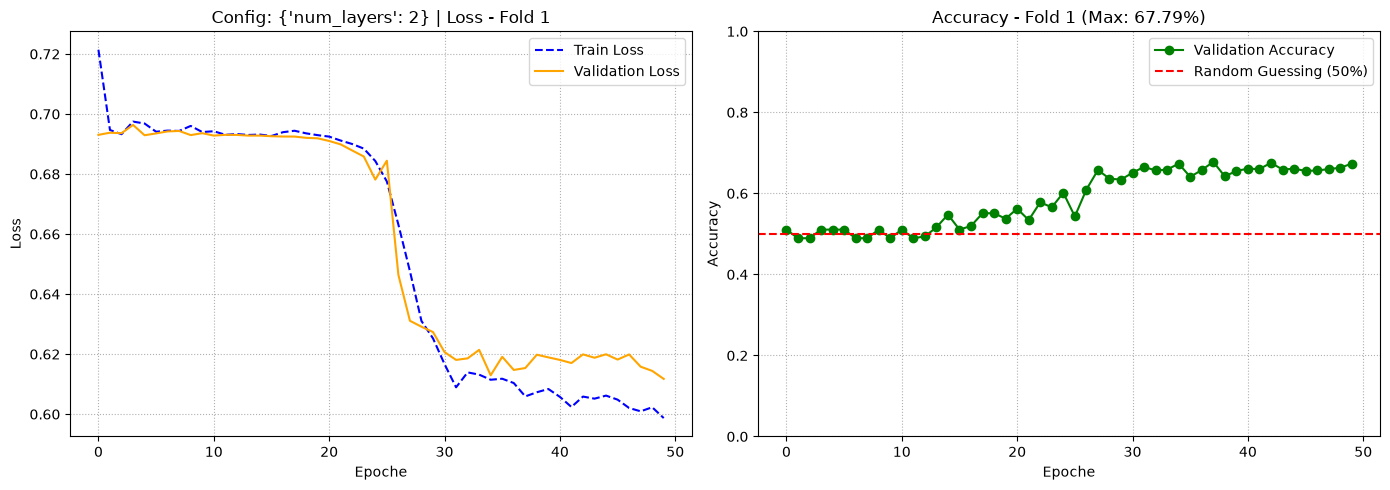


--- FOLD 2/5 ---
Epoch 01/50: train_loss=0.70468, train_acc=52.03%, val_loss=0.69374, val_acc=50.52% | LR: 0.001000
Epoch 02/50: train_loss=0.69681, train_acc=49.08%, val_loss=0.69559, val_acc=49.48% | LR: 0.001000
Epoch 03/50: train_loss=0.69548, train_acc=51.12%, val_loss=0.69318, val_acc=49.48% | LR: 0.001000
Epoch 04/50: train_loss=0.69776, train_acc=49.84%, val_loss=0.69311, val_acc=50.52% | LR: 0.001000
Epoch 05/50: train_loss=0.69372, train_acc=50.13%, val_loss=0.69429, val_acc=50.52% | LR: 0.001000
Epoch 06/50: train_loss=0.69506, train_acc=49.79%, val_loss=0.69548, val_acc=49.48% | LR: 0.001000
Epoch 07/50: train_loss=0.69681, train_acc=50.35%, val_loss=0.69406, val_acc=49.48% | LR: 0.001000
Epoch 08/50: train_loss=0.69413, train_acc=51.52%, val_loss=0.69417, val_acc=50.52% | LR: 0.001000
Epoch 09/50: train_loss=0.69344, train_acc=50.41%, val_loss=0.69298, val_acc=50.52% | LR: 0.001000
Epoch 10/50: train_loss=0.69469, train_acc=50.27%, val_loss=0.69365, val_acc=50.52% | LR: 0

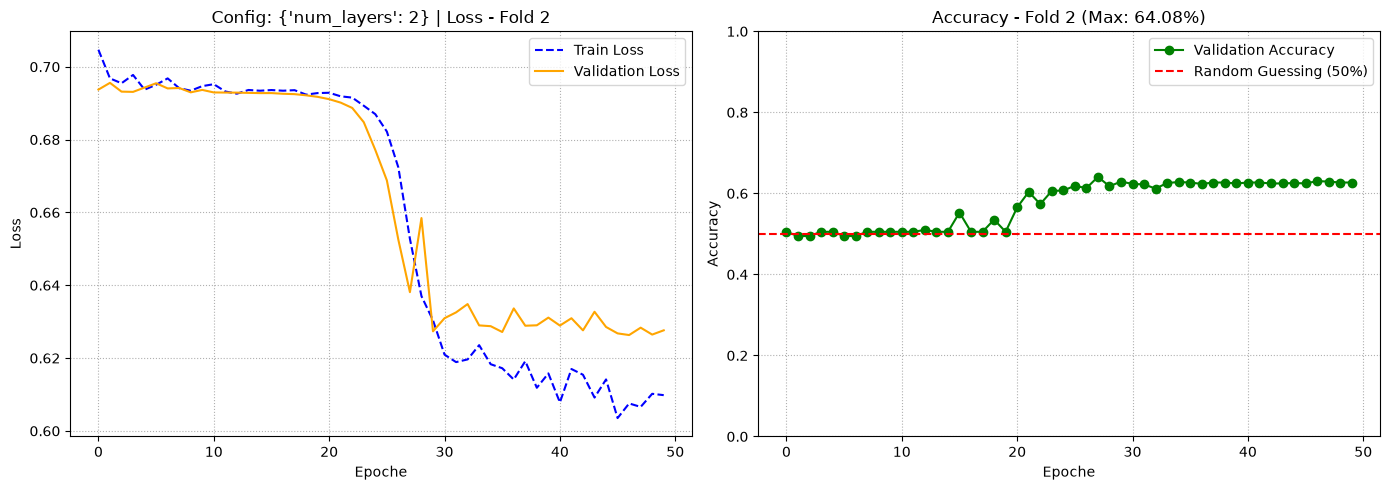


--- FOLD 3/5 ---
Epoch 01/50: train_loss=0.72759, train_acc=49.60%, val_loss=0.69374, val_acc=49.65% | LR: 0.001000
Epoch 02/50: train_loss=0.69767, train_acc=49.52%, val_loss=0.69357, val_acc=49.65% | LR: 0.001000
Epoch 03/50: train_loss=0.69749, train_acc=48.38%, val_loss=0.69396, val_acc=50.35% | LR: 0.001000
Epoch 04/50: train_loss=0.69792, train_acc=49.49%, val_loss=0.69325, val_acc=49.65% | LR: 0.001000
Epoch 05/50: train_loss=0.69416, train_acc=50.77%, val_loss=0.69427, val_acc=50.35% | LR: 0.001000
Epoch 06/50: train_loss=0.69414, train_acc=50.40%, val_loss=0.69398, val_acc=50.35% | LR: 0.001000
Epoch 07/50: train_loss=0.69407, train_acc=50.88%, val_loss=0.69315, val_acc=49.65% | LR: 0.001000
Epoch 08/50: train_loss=0.69337, train_acc=50.48%, val_loss=0.69365, val_acc=50.35% | LR: 0.001000
Epoch 09/50: train_loss=0.69442, train_acc=49.94%, val_loss=0.69633, val_acc=50.35% | LR: 0.001000
Epoch 10/50: train_loss=0.69414, train_acc=49.91%, val_loss=0.69306, val_acc=50.35% | LR: 0

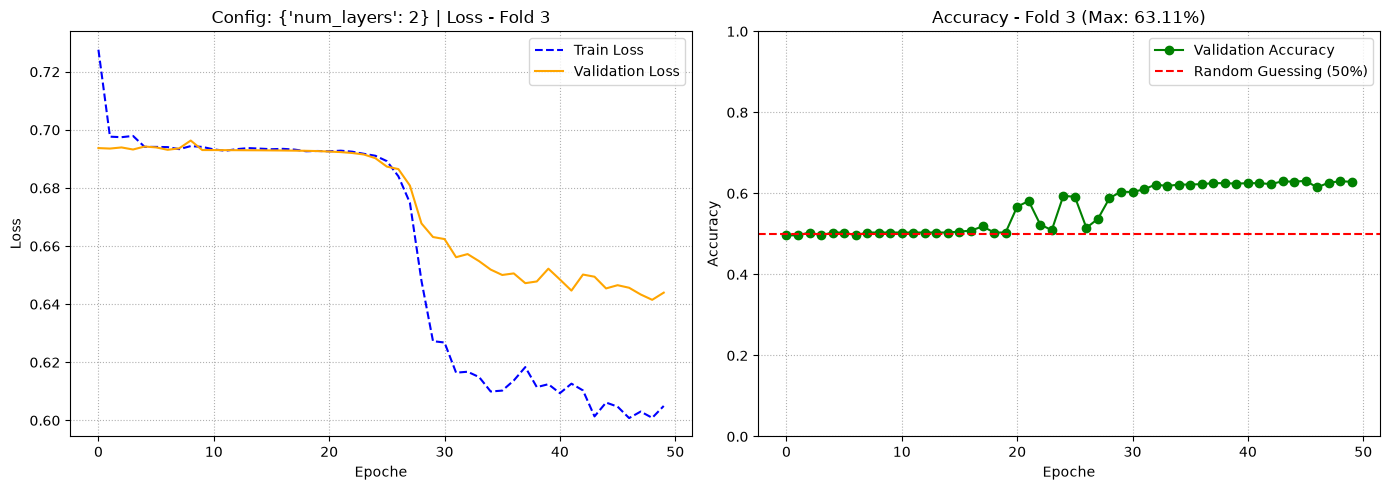


--- FOLD 4/5 ---
Epoch 01/50: train_loss=0.70486, train_acc=51.91%, val_loss=0.69420, val_acc=49.89% | LR: 0.001000
Epoch 02/50: train_loss=0.69790, train_acc=50.71%, val_loss=0.69684, val_acc=49.89% | LR: 0.001000
Epoch 03/50: train_loss=0.69356, train_acc=50.20%, val_loss=0.69320, val_acc=50.11% | LR: 0.001000
Epoch 04/50: train_loss=0.69534, train_acc=49.20%, val_loss=0.69342, val_acc=49.89% | LR: 0.001000
Epoch 05/50: train_loss=0.69505, train_acc=49.23%, val_loss=0.69311, val_acc=50.11% | LR: 0.001000
Epoch 06/50: train_loss=0.69384, train_acc=50.71%, val_loss=0.69731, val_acc=50.11% | LR: 0.001000
Epoch 07/50: train_loss=0.69516, train_acc=49.40%, val_loss=0.69307, val_acc=50.11% | LR: 0.001000
Epoch 08/50: train_loss=0.69412, train_acc=50.51%, val_loss=0.69704, val_acc=49.89% | LR: 0.001000
Epoch 09/50: train_loss=0.69454, train_acc=50.29%, val_loss=0.69360, val_acc=50.11% | LR: 0.001000
Epoch 10/50: train_loss=0.69339, train_acc=50.46%, val_loss=0.69396, val_acc=49.89% | LR: 0

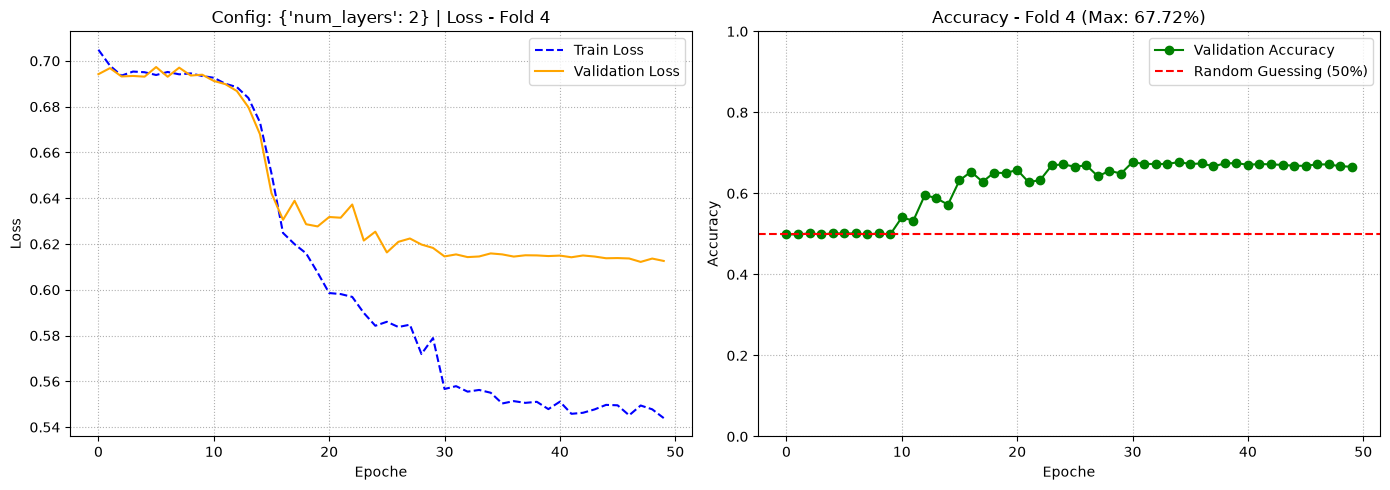


--- FOLD 5/5 ---
Epoch 01/50: train_loss=0.71703, train_acc=49.69%, val_loss=0.69358, val_acc=49.32% | LR: 0.001000
Epoch 02/50: train_loss=0.69889, train_acc=48.89%, val_loss=0.69428, val_acc=49.77% | LR: 0.001000
Epoch 03/50: train_loss=0.69620, train_acc=50.43%, val_loss=0.69314, val_acc=50.11% | LR: 0.001000
Epoch 04/50: train_loss=0.69598, train_acc=49.69%, val_loss=0.69313, val_acc=50.23% | LR: 0.001000
Epoch 05/50: train_loss=0.69476, train_acc=49.91%, val_loss=0.69328, val_acc=49.77% | LR: 0.001000
Epoch 06/50: train_loss=0.69421, train_acc=49.49%, val_loss=0.69320, val_acc=49.77% | LR: 0.001000
Epoch 07/50: train_loss=0.69380, train_acc=50.49%, val_loss=0.69739, val_acc=50.23% | LR: 0.001000
Epoch 08/50: train_loss=0.69507, train_acc=50.17%, val_loss=0.69374, val_acc=49.77% | LR: 0.001000
Epoch 09/50: train_loss=0.69441, train_acc=49.57%, val_loss=0.69333, val_acc=49.77% | LR: 0.001000
Epoch 10/50: train_loss=0.69556, train_acc=49.94%, val_loss=0.69314, val_acc=50.23% | LR: 0

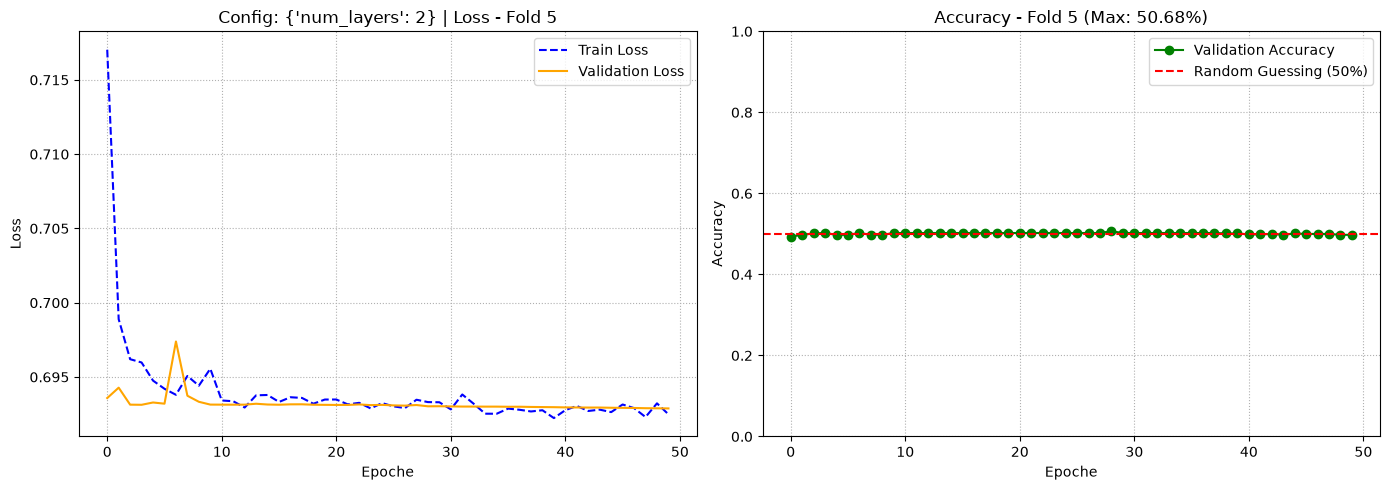


🏁 RISULTATO FINALE CONFIGURAZIONE {'num_layers': 2}:
📊 Accuracy media: 62.67% (± 6.29%)

--- COMBINAZIONE 2/2 ---
Parametri attuali: {'num_layers': 3}

--- FOLD 1/5 ---
Epoch 01/50: train_loss=0.71051, train_acc=49.33%, val_loss=0.69571, val_acc=51.07% | LR: 0.001000
Epoch 02/50: train_loss=0.69789, train_acc=48.61%, val_loss=0.69300, val_acc=51.07% | LR: 0.001000
Epoch 03/50: train_loss=0.69534, train_acc=49.27%, val_loss=0.69959, val_acc=48.93% | LR: 0.001000
Epoch 04/50: train_loss=0.69816, train_acc=48.81%, val_loss=0.69293, val_acc=51.07% | LR: 0.001000
Epoch 05/50: train_loss=0.69529, train_acc=49.01%, val_loss=0.69416, val_acc=48.93% | LR: 0.001000
Epoch 06/50: train_loss=0.69438, train_acc=50.16%, val_loss=0.69315, val_acc=48.93% | LR: 0.001000
Epoch 07/50: train_loss=0.69461, train_acc=49.81%, val_loss=0.69411, val_acc=51.07% | LR: 0.001000
Epoch 08/50: train_loss=0.69452, train_acc=48.41%, val_loss=0.69295, val_acc=51.07% | LR: 0.001000
Epoch 09/50: train_loss=0.69419, train

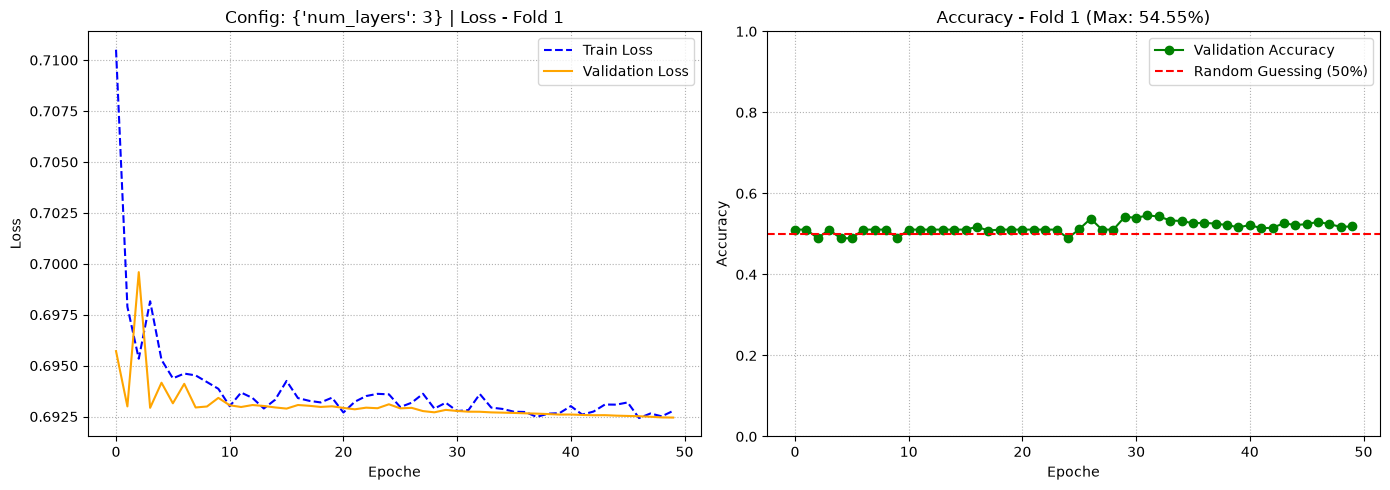


--- FOLD 2/5 ---
Epoch 01/50: train_loss=0.71727, train_acc=50.24%, val_loss=0.69332, val_acc=49.48% | LR: 0.001000
Epoch 02/50: train_loss=0.70171, train_acc=49.59%, val_loss=0.69534, val_acc=49.48% | LR: 0.001000
Epoch 03/50: train_loss=0.69523, train_acc=51.09%, val_loss=0.69370, val_acc=49.48% | LR: 0.001000
Epoch 04/50: train_loss=0.69685, train_acc=48.74%, val_loss=0.69715, val_acc=49.48% | LR: 0.001000
Epoch 05/50: train_loss=0.69726, train_acc=48.28%, val_loss=0.69308, val_acc=50.52% | LR: 0.001000
Epoch 06/50: train_loss=0.69300, train_acc=51.55%, val_loss=0.69768, val_acc=49.48% | LR: 0.001000
Epoch 07/50: train_loss=0.69585, train_acc=48.68%, val_loss=0.69306, val_acc=50.52% | LR: 0.001000
Epoch 08/50: train_loss=0.69432, train_acc=49.70%, val_loss=0.69465, val_acc=49.48% | LR: 0.001000
Epoch 09/50: train_loss=0.69597, train_acc=49.25%, val_loss=0.69364, val_acc=50.52% | LR: 0.001000
Epoch 10/50: train_loss=0.69480, train_acc=49.93%, val_loss=0.69318, val_acc=49.48% | LR: 0

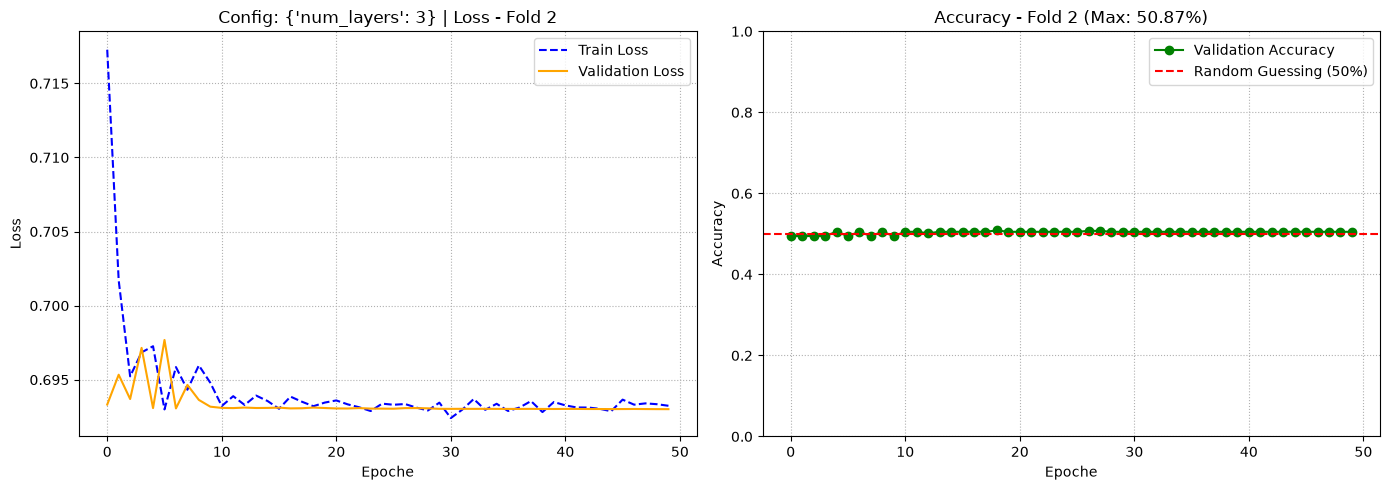


--- FOLD 3/5 ---
Epoch 01/50: train_loss=0.71561, train_acc=49.66%, val_loss=0.69885, val_acc=49.65% | LR: 0.001000
Epoch 02/50: train_loss=0.69732, train_acc=49.12%, val_loss=0.69343, val_acc=50.35% | LR: 0.001000
Epoch 03/50: train_loss=0.69691, train_acc=50.14%, val_loss=0.69493, val_acc=50.35% | LR: 0.001000
Epoch 04/50: train_loss=0.69633, train_acc=49.38%, val_loss=0.69412, val_acc=49.65% | LR: 0.001000
Epoch 05/50: train_loss=0.69356, train_acc=50.60%, val_loss=0.69518, val_acc=49.65% | LR: 0.001000
Epoch 06/50: train_loss=0.69490, train_acc=50.11%, val_loss=0.69391, val_acc=50.35% | LR: 0.001000
Epoch 07/50: train_loss=0.69431, train_acc=49.55%, val_loss=0.69413, val_acc=49.65% | LR: 0.001000
Epoch 08/50: train_loss=0.69664, train_acc=48.98%, val_loss=0.69354, val_acc=50.35% | LR: 0.001000
Epoch 09/50: train_loss=0.69390, train_acc=48.84%, val_loss=0.69308, val_acc=50.35% | LR: 0.001000
Epoch 10/50: train_loss=0.69460, train_acc=48.67%, val_loss=0.69322, val_acc=49.65% | LR: 0

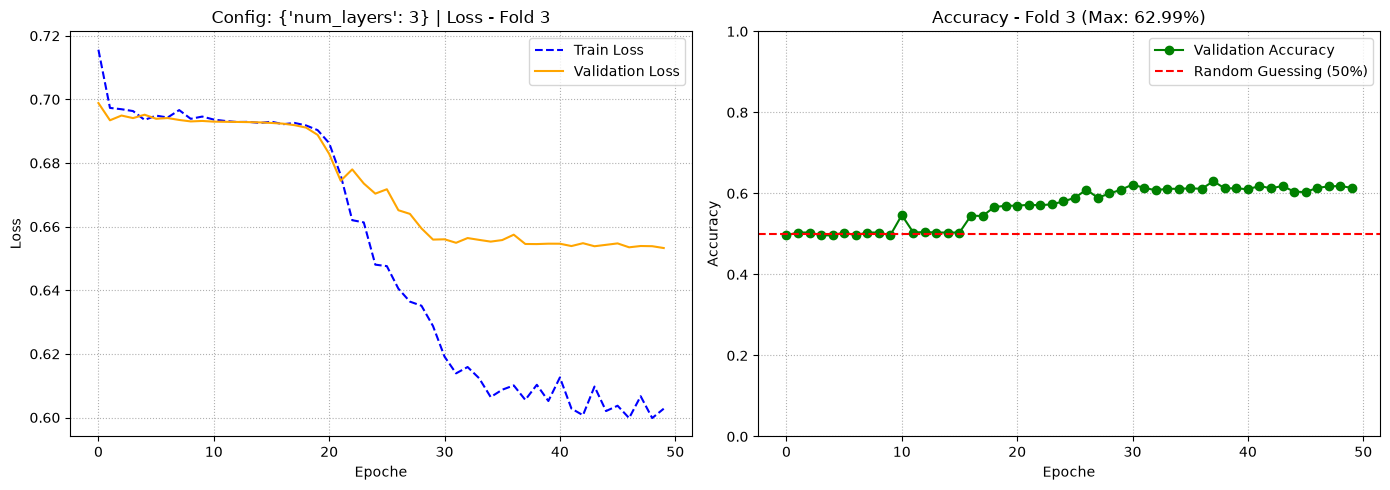


--- FOLD 4/5 ---
Epoch 01/50: train_loss=0.72280, train_acc=48.80%, val_loss=0.69797, val_acc=49.89% | LR: 0.001000
Epoch 02/50: train_loss=0.69646, train_acc=49.20%, val_loss=0.69324, val_acc=50.11% | LR: 0.001000
Epoch 03/50: train_loss=0.69667, train_acc=49.66%, val_loss=0.69621, val_acc=50.11% | LR: 0.001000
Epoch 04/50: train_loss=0.69447, train_acc=50.66%, val_loss=0.69322, val_acc=49.89% | LR: 0.001000
Epoch 05/50: train_loss=0.69394, train_acc=50.51%, val_loss=0.69374, val_acc=49.89% | LR: 0.001000
Epoch 06/50: train_loss=0.69479, train_acc=48.66%, val_loss=0.69327, val_acc=50.11% | LR: 0.001000
Epoch 07/50: train_loss=0.69531, train_acc=49.34%, val_loss=0.69321, val_acc=50.11% | LR: 0.001000
Epoch 08/50: train_loss=0.69416, train_acc=49.40%, val_loss=0.69312, val_acc=50.34% | LR: 0.001000
Epoch 09/50: train_loss=0.69473, train_acc=49.49%, val_loss=0.69518, val_acc=50.11% | LR: 0.001000
Epoch 10/50: train_loss=0.69352, train_acc=50.63%, val_loss=0.69328, val_acc=50.11% | LR: 0

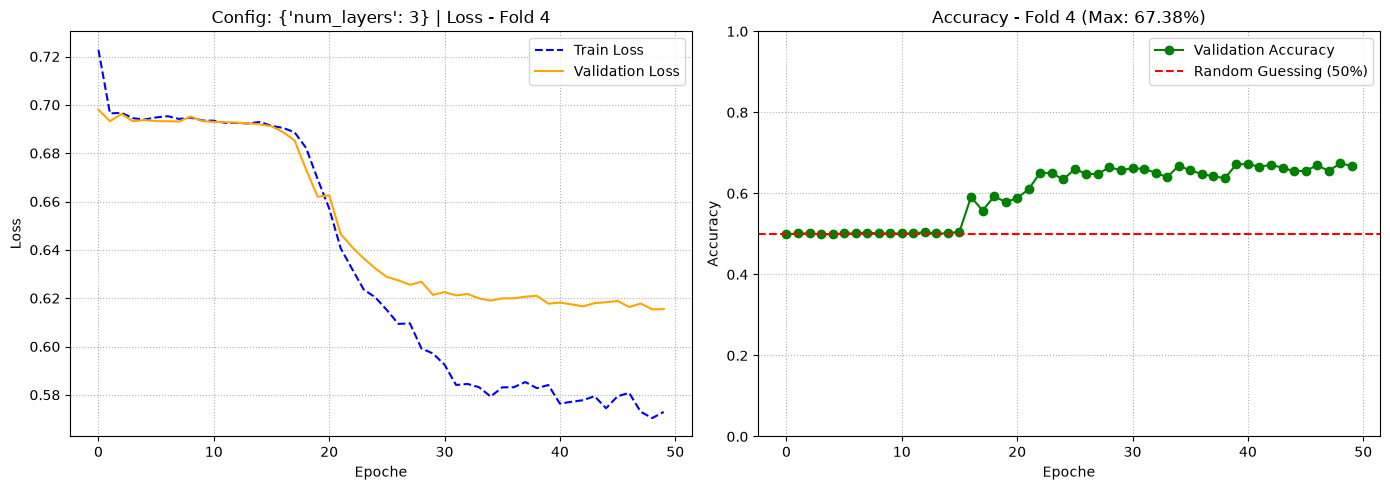


--- FOLD 5/5 ---
Epoch 01/50: train_loss=0.71777, train_acc=49.74%, val_loss=0.69314, val_acc=50.23% | LR: 0.001000
Epoch 02/50: train_loss=0.69538, train_acc=49.69%, val_loss=0.70062, val_acc=50.23% | LR: 0.001000
Epoch 03/50: train_loss=0.69766, train_acc=49.74%, val_loss=0.69453, val_acc=50.23% | LR: 0.001000
Epoch 04/50: train_loss=0.69456, train_acc=49.97%, val_loss=0.69314, val_acc=50.23% | LR: 0.001000
Epoch 05/50: train_loss=0.69627, train_acc=49.80%, val_loss=0.69354, val_acc=49.77% | LR: 0.001000
Epoch 06/50: train_loss=0.69489, train_acc=49.80%, val_loss=0.69321, val_acc=50.23% | LR: 0.001000
Epoch 07/50: train_loss=0.69501, train_acc=49.14%, val_loss=0.69315, val_acc=50.23% | LR: 0.001000
Epoch 08/50: train_loss=0.69485, train_acc=49.74%, val_loss=0.69483, val_acc=49.77% | LR: 0.001000
Epoch 09/50: train_loss=0.69552, train_acc=49.43%, val_loss=0.69349, val_acc=50.23% | LR: 0.001000
Epoch 10/50: train_loss=0.69358, train_acc=51.23%, val_loss=0.69316, val_acc=49.77% | LR: 0

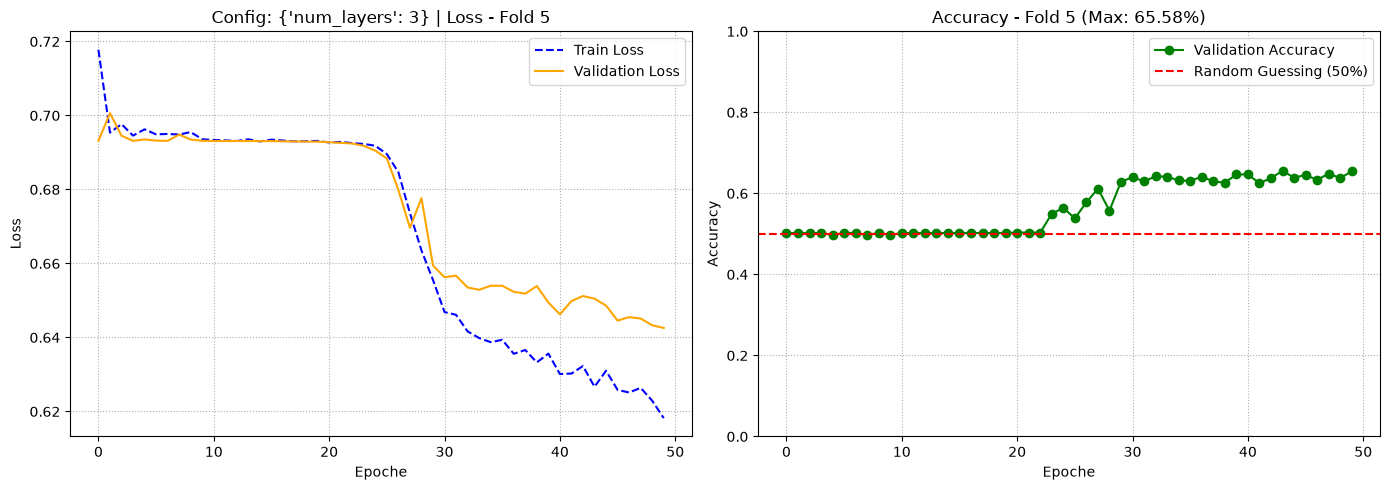


🏁 RISULTATO FINALE CONFIGURAZIONE {'num_layers': 3}:
📊 Accuracy media: 60.27% (± 6.44%)

🎉 RIEPILOGO COMPLETO GRID SEARCH:
Parametri {'num_layers': 2} ➔ Accuracy media: 62.67% (± 6.29%)
Parametri {'num_layers': 3} ➔ Accuracy media: 60.27% (± 6.44%)


In [ ]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR
import itertools

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")

# Griglia dei parametri da testare
param_grid = {
    'num_layers': [2, 3]
}

keys = param_grid.keys()
values = param_grid.values()
param_combinations = [dict(zip(keys, combination)) for combination in itertools.product(*values)]

# 2. Parametri di Configurazione
BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Dizionario per memorizzare i risultati finali
grid_results = {}
best_global_acc = 0.0
best_model_state = None

# ==========================================
# CICLO PRINCIPALE DELLA GRID SEARCH
# ==========================================
for i, params in enumerate(param_combinations, 1):
    print(f"\n==========================================")
    print(f"--- COMBINAZIONE {i}/{len(param_combinations)} ---")
    print(f"Parametri attuali: {params}")
    print(f"==========================================")
    
    comb_fold_accuracies = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
        
        print(f"\n--- FOLD {fold + 1}/5 ---")

        # A. Split dei dati grezzi
        X_train_raw = X_training_validation_raw[train_idx]
        y_train = y_training_validation[train_idx]
        X_val_raw = X_training_validation_raw[val_idx]
        y_val = y_training_validation[val_idx]

        # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set
        train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
        train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)

        # C. Normalizzazione + Data Augmentation solo sul Train
        X_train_norm = (X_train_raw - train_mean) / (train_std + EPSILON)
        noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
        X_train_final = X_train_norm + noise

        # D. Normalizzazione pura sul Validation Set
        X_val_final = (X_val_raw - train_mean) / (train_std + EPSILON)

        # E. Creazione Dataset e DataLoader
        train_dataset = EEGDataset(X_train_final, y_train)
        val_dataset = EEGDataset(X_val_final, y_val)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

        # F. Inizializzazione del Modello con i parametri correnti
        model = F_CTrans_modify(
            num_channels=64, 
            d_model=128, 
            nhead=8, 
            d_ff=512, 
            dropout=0.3, 
            num_layers=params['num_layers'], 
            num_classes=2
        ).to(device)
    
        # G. Ottimizzatore, Loss e Scheduler
        criterion = nn.CrossEntropyLoss()
        optimizer = optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=WEIGHT_DECAY)
        scheduler = MultiStepLR(optimizer, milestones=[10, 30], gamma=0.1)
    
        # H. Trainer personalizzato
        trainer = EEGTrainer(
            model=model, 
            criterion=criterion, 
            optimizer=optimizer,  
            device=device
        )

        # I. Training e Validazione
        best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
            train_loader=train_loader, 
            val_loader=val_loader, 
            epochs=EPOCHS,
            scheduler=scheduler
        )

        comb_fold_accuracies.append(best_val_acc)
        print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

        # Salvataggio del modello migliore assoluto
        if best_val_acc > best_global_acc:
            best_global_acc = best_val_acc
            best_model_state = model.state_dict()

        # ==========================================
        # L. PLOT DELLE CURVE PER OGNI FOLD
        # ==========================================
        plt.figure(figsize=(14, 5))

        plt.subplot(1, 2, 1)
        plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
        plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
        plt.title(f'Config: {params} | Loss - Fold {fold + 1}')
        plt.xlabel('Epoche')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.subplot(1, 2, 2)
        plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
        plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
        plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
        plt.xlabel('Epoche')
        plt.ylabel('Accuracy')
        plt.ylim(0.0, 1.0)
        plt.legend()
        plt.grid(True, linestyle=':')

        plt.tight_layout()
        plt.show()  # 👈 Mostra il grafico del fold corrente in tempo reale

    # Calcolo e salvataggio delle medie finali per questa combinazione
    mean_acc = np.mean(comb_fold_accuracies)
    std_acc = np.std(comb_fold_accuracies)
    grid_results[str(params)] = (mean_acc, std_acc)
    
    print(f"\n🏁 RISULTATO FINALE CONFIGURAZIONE {params}:")
    print(f"📊 Accuracy media: {mean_acc*100:.2f}% (± {std_acc*100:.2f}%)")

print(f"\n🎉 RIEPILOGO COMPLETO GRID SEARCH:")
for config, (mean, std) in grid_results.items():
    print(f"Parametri {config} ➔ Accuracy media: {mean*100:.2f}% (± {std*100:.2f}%)")

# f_CTrans con ReduceLROnPlateau (uso PE differenti per il ramo spaziale e temporale)

## Provo grid search

In [ ]:


from torch.optim.lr_scheduler import ReduceLROnPlateau


import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.model_selection import GroupKFold
import matplotlib.pyplot as plt
from torch.optim.lr_scheduler import MultiStepLR

# 1. Configurazione del Dispositivo (MPS / CUDA / CPU)
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print("🚀 Dispositivo rilevato: GPU Apple Silicon (MPS)")
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print("🚀 Dispositivo rilevato: GPU NVIDIA (CUDA)")
else:
    device = torch.device('cpu')
    print("⚠️ Dispositivo rilevato: CPU")



# 2. Parametri di Configurazione Ottimizzati
BATCH_SIZE = 64       
EPOCHS = 50           
LR = 0.001       
WEIGHT_DECAY = 0.0001   
ALPHA_NOISE = 0.01     
EPSILON = 1e-8

gkf = GroupKFold(n_splits=5)

# Liste per raccogliere le metriche di tutti i fold
fold_accuracies = []
best_global_acc = 0.0
best_model_state = None

# ==========================================
# 3. CICLO DI TRAINING CON GROUPKFOLD
# ==========================================
for fold, (train_idx, val_idx) in enumerate(gkf.split(X_training_validation_raw, y_training_validation, subjects_ids_training_validation)):
    
    print(f"\n--- INIZIO TRAINING & VALIDAZIONE - FOLD {fold + 1}/5 ---")

    # A. Split dei dati grezzi
    X_train_raw = X_training_validation_raw[train_idx]
    y_train = y_training_validation[train_idx]
    
    X_val_raw = X_training_validation_raw[val_idx]
    y_val = y_training_validation[val_idx]
    
    X_train_tensor = torch.tensor(X_train_raw, dtype=torch.float32)
    X_val_tensor = torch.tensor(X_val_raw, dtype=torch.float32)


    # B. Calcolo Media e Std per-canale ESCLUSIVAMENTE sul Training Set (Prevenzione Data Leakage)
    train_mean = np.mean(X_train_raw, axis=(0, 2), keepdims=True)  
    train_std = np.std(X_train_raw, axis=(0, 2), keepdims=True)
    epsilon = 1e-8

    # C. Normalizzazione + Data Augmentation (Rumore Gaussiano) solo sul Train
    X_train_norm = (X_train_raw - train_mean) / (train_std + epsilon)
    noise = ALPHA_NOISE * np.random.randn(*X_train_norm.shape)
    X_train_final = X_train_norm + noise

    # D. Normalizzazione pura sul Validation Set (usando media e std del Train)
    X_val_final = (X_val_raw - train_mean) / (train_std + epsilon)

    # E. Creazione Dataset e DataLoader PyTorch
    train_dataset = EEGDataset(X_train_final, y_train)
    val_dataset = EEGDataset(X_val_final, y_val)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
    


    # F. Inizializzazione del Modello 
    # NOTA: Assicurati che d_model corrisponda ai canali in uscita del CNN module o gestiscilo con una Linear layer.
    model = F_CTransconconcatenazioneeMLPdiverso(num_channels = 64 ,d_model= 128, nhead = 8 , d_ff =512, dropout =0.3, num_layers = 3, num_classes =2).to(device)
   
    # G. Ottimizzatore, Loss e Scheduler
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=LR ,betas=(0.9, 0.95),weight_decay=WEIGHT_DECAY)
    scheduler = ReduceLROnPlateau(
        optimizer, 
        mode='max',      # Vogliamo MASSIMIZZARE l'accuratezza
        factor=0.5,      # Dimezza il learning rate quando ci si blocca
        patience=5,      # Quante epoche aspettare prima di intervenire se non migliora
        min_lr=1e-6  # Soglia minima sotto cui non scendere
          # Ti stampa un messaggio quando riduce il lr
    )
  
    # H. Trainer personalizzato
    trainer = EEGTrainer(
        model=model, 
        criterion=criterion, 
        optimizer=optimizer,  
        device=device
    )

    print("Controllo rapido del batch di training...")
    for inputs, labels in train_loader:
        print(f"Forma batch input: {inputs.shape} (Atteso: [Batch, 64, 641])")
        print(f"Forma batch labels: {labels.shape} (Atteso: [Batch])")
        print(f"Tipo dati labels: {labels.dtype} (Atteso: torch.int64)")
        
        # Test di forward pass per verificare che non ci siano crash di shape
        outputs, _ = model(inputs.to(device))
        print(f"Forma output modello: {outputs.shape} (Atteso: [Batch, 2])")
        break
    print("Diagnostica superata con successo! Avvio le epoche...\n")

    # I. Training e Validazione con Early Stopping integrato
    best_val_acc, train_losses, val_losses, val_accuracies = trainer.train_and_validate(
        train_loader=train_loader, 
        val_loader=val_loader, 
        epochs=EPOCHS,
        scheduler=scheduler
    )

    fold_accuracies.append(best_val_acc)
    print(f"✅ Fold {fold + 1} completato | Miglior Val Acc: {best_val_acc*100:.2f}%")

    # Salvataggio del modello migliore assoluto
    if best_val_acc > best_global_acc:
        best_global_acc = best_val_acc
        best_model_state = model.state_dict()

    # ==========================================
    # L. PLOT DELLE CURVE DI LOSS E ACCURACY
    # ==========================================
    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, linestyle='--', color='blue', label='Train Loss')
    plt.plot(val_losses, linestyle='-', color='orange', label='Validation Loss')
    plt.title(f'Loss - Fold {fold + 1}')
    plt.xlabel('Epoche')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.subplot(1, 2, 2)
    plt.plot(val_accuracies, marker='o', color='green', label='Validation Accuracy')
    plt.axhline(y=0.5, color='red', linestyle='--', label='Random Guessing (50%)')
    plt.title(f'Accuracy - Fold {fold + 1} (Max: {max(val_accuracies)*100:.2f}%)')
    plt.xlabel('Epoche')
    plt.ylabel('Accuracy')
    plt.ylim(0.0, 1.0)
    plt.legend()
    plt.grid(True, linestyle=':')

    plt.tight_layout()
    plt.show()
    break
    
print(f"\n🎉 TRAINING COMPLETATO SU TUTTI I FOLD!")
print(f"📊 Accuracy media cross-validation: {np.mean(fold_accuracies)*100:.2f}% (± {np.std(fold_accuracies)*100:.2f}%)")